# Role 3 — Experimental Comparison & Final Analysis
**Secure Blockchain Consensus Using ML-Based Trust-Aware Validator Selection**

Run A: `Weight = Stake` · Run B: `Weight = Stake × Trust Score` (1000 selections each, 100 validators).

## 1. Load the data

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

A = pd.read_csv("run_A_traditional_selection_log.csv")
B = pd.read_csv("run_B_trust_aware_selection_log.csv")
switch = pd.read_csv("onoff_validator_switch_points.csv")

print("Run A:", A.shape, "| Run B:", B.shape, "| on-off validators:", len(switch))
print("Missing values  A:", int(A.isna().sum().sum()), " B:", int(B.isna().sum().sum()))
B.head()

Run A: (1000, 3) | Run B: (1000, 4) | on-off validators: 10
Missing values  A: 0  B: 0


## 2. Malicious Selection Rate (H1)
`MSR = malicious selections / 1000`, `HSR = 1 − MSR` (malicious ⇔ `selected_validator_true_label == 0`). Computed from the raw logs, not taken from the preliminary note.

In [ ]:
def rates(df):
    mal = int((df["selected_validator_true_label"] == 0).sum())
    msr = mal / len(df)
    return mal, msr, 1 - msr

malA, msrA, hsrA = rates(A)
malB, msrB, hsrB = rates(B)

print(f"Run A (Stake only)     : malicious = {malA:4d}  MSR = {msrA:.1%}  HSR = {hsrA:.1%}")
print(f"Run B (Stake x Trust)  : malicious = {malB:4d}  MSR = {msrB:.1%}  HSR = {hsrB:.1%}")
print(f"Absolute drop in MSR   : {(msrA-msrB)*100:.1f} percentage points")
print(f"Relative reduction     : {(msrA-msrB)/msrA:.1%}")

# Two-proportion z-test: is the drop bigger than random noise?
p = (malA + malB) / (len(A) + len(B))
z = (msrA - msrB) / np.sqrt(p * (1 - p) * (1/len(A) + 1/len(B)))
print(f"Two-proportion z-score : {z:.2f}  (|z| > 2.58 => significant at 1%)")

Run A (Stake only)     : malicious =  204  MSR = 20.4%  HSR = 79.6%
Run B (Stake x Trust)  : malicious =   86  MSR = 8.6%  HSR = 91.4%
Absolute drop in MSR   : 11.8 percentage points
Relative reduction     : 57.8%
Two-proportion z-score : 7.49  (|z| > 2.58 => significant at 1%)


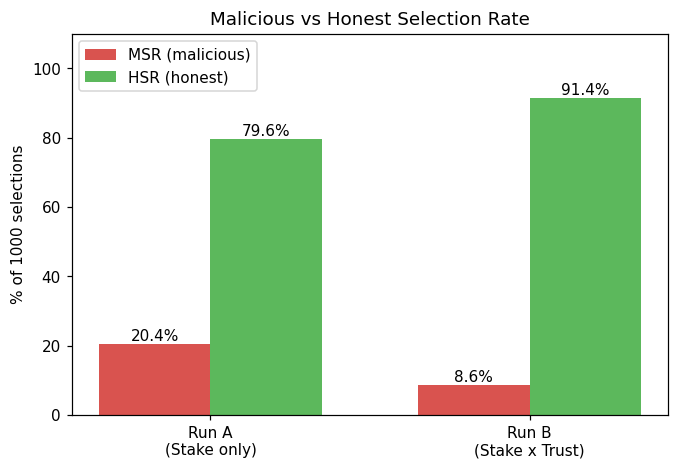

In [ ]:
labels = ["Run A\n(Stake only)", "Run B\n(Stake x Trust)"]
x = np.arange(2); w = 0.35
fig, ax = plt.subplots(figsize=(7, 4.5))
b1 = ax.bar(x - w/2, [msrA*100, msrB*100], w, label="MSR (malicious)", color="#d9534f")
b2 = ax.bar(x + w/2, [hsrA*100, hsrB*100], w, label="HSR (honest)", color="#5cb85c")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 1, f"{r.get_height():.1f}%", ha="center")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 110)
ax.set_ylabel("% of 1000 selections")
ax.set_title("Malicious vs Honest Selection Rate")
ax.legend(); plt.show()

## 3. Decentralization check via Gini coefficient (H3)
Gini of the *selection count per validator* (all 100 validators, zeros included). 0 = perfectly equal, 1 = one validator gets everything.

In [ ]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x); i = np.arange(1, n + 1)
    return (2 * np.sum(i * x)) / (n * x.sum()) - (n + 1) / n

ids = range(1, 101)
cntA = A["selected_validator_id"].value_counts().reindex(ids, fill_value=0)
cntB = B["selected_validator_id"].value_counts().reindex(ids, fill_value=0)

gA, gB = gini(cntA), gini(cntB)
print(f"Gini Run A: {gA:.3f}   (max picks by one validator: {cntA.max()}, never selected: {(cntA==0).sum()})")
print(f"Gini Run B: {gB:.3f}   (max picks by one validator: {cntB.max()}, never selected: {(cntB==0).sum()})")
trend = "MORE" if gB > gA else "LESS"
print(f"\n=> Run B selection is {trend} concentrated than Run A (change = {gB-gA:+.3f}).")
print("Top-5 validators  A:", cntA.nlargest(5).to_dict())
print("Top-5 validators  B:", cntB.nlargest(5).to_dict())

Gini Run A: 0.532   (max picks by one validator: 58, never selected: 5)
Gini Run B: 0.576   (max picks by one validator: 64, never selected: 14)

=> Run B selection is MORE concentrated than Run A (change = +0.044).
Top-5 validators  A: {55: 58, 64: 54, 8: 50, 3: 36, 77: 35}
Top-5 validators  B: {8: 64, 64: 54, 79: 43, 77: 41, 1: 38}


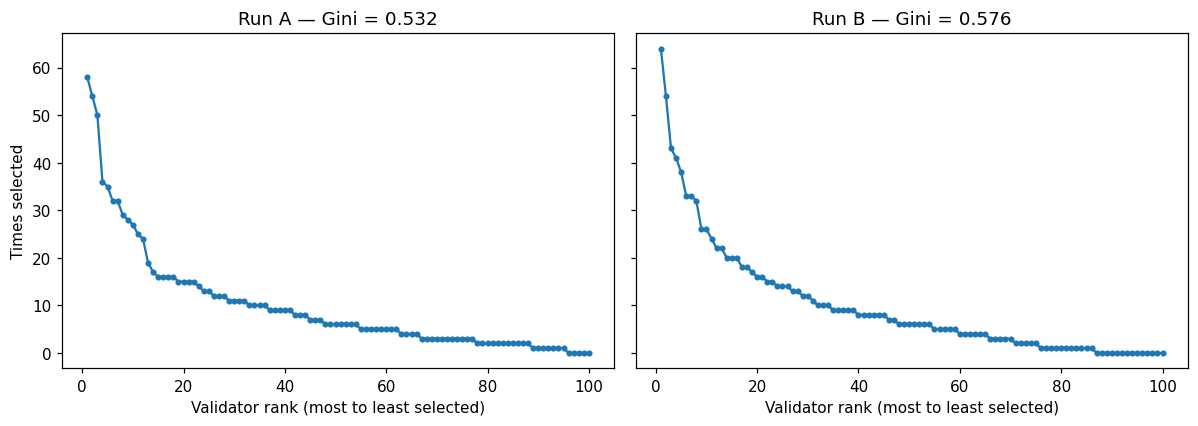

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, cnt, g, name in zip(axes, (cntA, cntB), (gA, gB), ("Run A", "Run B")):
    ax.plot(np.arange(1, 101), np.sort(cnt.values)[::-1], marker=".")
    ax.set_title(f"{name} — Gini = {g:.3f}")
    ax.set_xlabel("Validator rank (most to least selected)")
axes[0].set_ylabel("Times selected")
plt.tight_layout(); plt.show()

## 4. Trust score reaction to betrayal (threat model)
Run B's `trust_score_of_selected` for on-off attackers, only at the transactions where they were actually selected. Red line = defection point. Validators 6, 47 and 90 are shown because they have several selections both before and after defecting (others have too few points to plot a trajectory).

In [ ]:
sel = B[B["selected_validator_id"].isin(switch["validator_id"])]
summary = []
for _, r in switch.iterrows():
    v = sel[sel["selected_validator_id"] == r["validator_id"]]
    pre = v[v["transaction_id"] < r["defection_transaction_id"]]
    post = v[v["transaction_id"] >= r["defection_transaction_id"]]
    summary.append((r["validator_id"], r["defection_transaction_id"], len(pre), len(post),
                    pre["trust_score_of_selected"].mean(), post["trust_score_of_selected"].mean()))
print(pd.DataFrame(summary, columns=["validator", "defect_tx", "n_before", "n_after",
                                     "avg_trust_before", "avg_trust_after"]).round(3).to_string(index=False))

 validator  defect_tx  n_before  n_after  avg_trust_before  avg_trust_after
         6        266         4        4             1.000            0.486
        11        287         0        1               NaN            0.312
        14        685         3        2             1.000            0.869
        19        615         1        4             0.998            0.824
        32        759        12        1             1.000            0.818
        44        297         2        1             0.999            0.583
        47        624         6        8             1.000            0.807
        66        781        20        4             0.996            0.912
        89        793         0        0               NaN              NaN
        90        450         5        7             1.000            0.643


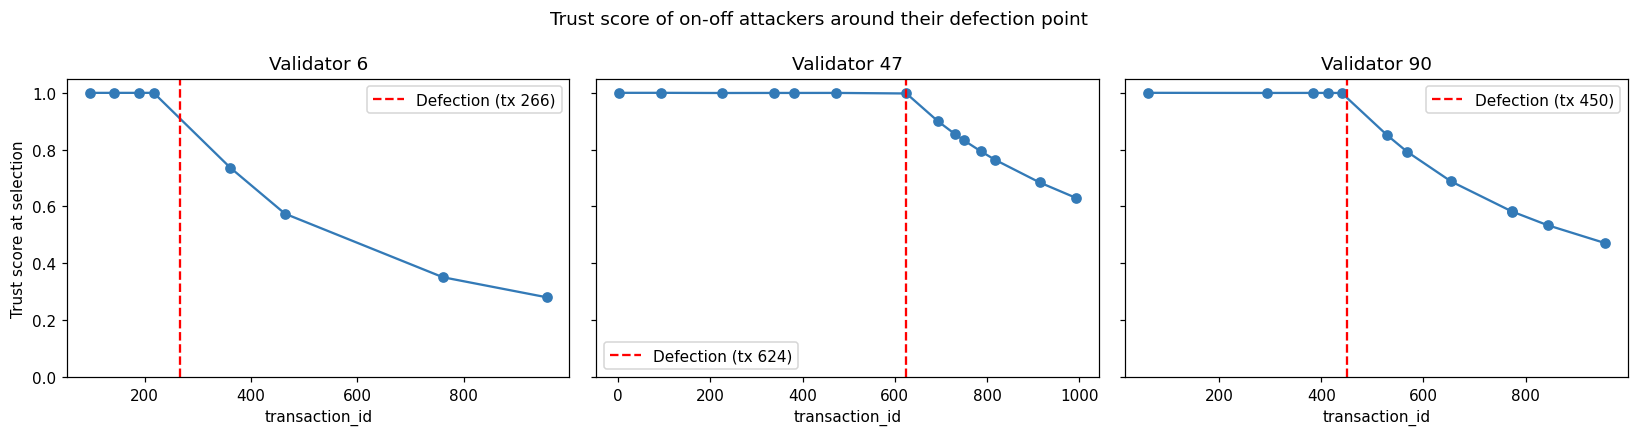

In [ ]:
chosen = [6, 47, 90]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, vid in zip(axes, chosen):
    d = int(switch.loc[switch["validator_id"] == vid, "defection_transaction_id"].iloc[0])
    v = B[B["selected_validator_id"] == vid].sort_values("transaction_id")
    ax.plot(v["transaction_id"], v["trust_score_of_selected"], "o-", color="#337ab7")
    ax.axvline(d, color="red", linestyle="--", label=f"Defection (tx {d})")
    ax.set_title(f"Validator {vid}"); ax.set_xlabel("transaction_id"); ax.set_ylim(0, 1.05); ax.legend()
axes[0].set_ylabel("Trust score at selection")
fig.suptitle("Trust score of on-off attackers around their defection point")
plt.tight_layout(); plt.show()

## 5. Conclusion

- **H1 supported.** Malicious Selection Rate fell from **20.4% (Run A) to 8.6% (Run B)**: an 11.8-point drop, ~58% relative reduction, statistically significant (z ≈ 7.5). The preliminary numbers were verified from the raw logs.
- **H3 not supported (trade-off exists).** Gini rose from **0.532 to 0.576**, so selection is *somewhat more concentrated* under trust-aware selection (14 validators never selected vs 5 in Run A). Note Run A is already fairly unequal because stake itself is unequal. Report this honestly as a cost of the approach, not a win.
- **Threat model.** After defecting, on-off attackers' trust scores drop (e.g. validator 6: ~1.0 -> ~0.49 average), so the system does detect betrayal, but the reaction is gradual, not instant, and some post-defection selections still occur.
- **Limitations.** Single simulation run per system (no repeated seeds), and few selection points per on-off validator, so the on-off analysis is illustrative rather than statistical.